In [1]:
import numpy as np
from scipy.spatial import cKDTree
import pandas as pd

def find_closest_pair(adata, batch_name, 
                      cell_type_A=None, gene_A=None, 
                      cell_type_B=None, gene_B=None):
    """
    Find the closest pair of cells (A, B) in a specified batch based on flexible filtering criteria.
    
    Parameters:
    -----------
    adata : AnnData
        AnnData object containing spatial transcriptomics data.
    batch_name : str
        Sample batch name (corresponds to adata.obs['batch']).
        
    cell_type_A / cell_type_B : str, list of str, or None
        Target cell types.
        - If list: OR logic (e.g., ["T", "B"] -> T or B both acceptable).
        - If None: no cell type restriction.
        
    gene_A / gene_B : str, list of str, or None
        Target genes.
        - If list: AND logic (e.g., ["CCR7", "CXCL13"] -> must be co-expressed).
        - If None: no gene expression restriction.
        
    Returns:
    --------
    tuple: (name_A, name_B)
        Names of the closest cell pair satisfying the criteria. Returns (None, None) if no qualifying cells exist in either group.
    """
    
    def get_mask(batch_adata, cell_types, genes):
        """
        Build a boolean mask for filtering cells.
        """
        mask = pd.Series(True, index=batch_adata.obs_names)
        
        # 1. Cell type filtering (OR logic)
        if cell_types is not None:
            # Normalize to list for uniform handling
            if isinstance(cell_types, str):
                cell_types = [cell_types]
            
            # True if obs['cell_type'] matches any value in the list
            type_mask = batch_adata.obs['type'].isin(cell_types)
            mask = mask & type_mask
            
        # 2. Gene expression filtering (AND logic)
        if genes is not None:
            # Normalize to list for uniform handling
            if isinstance(genes, str):
                genes = [genes]
                
            # Check whether genes exist in the data
            valid_genes = [g for g in genes if g in batch_adata.var_names]
            if len(valid_genes) < len(genes):
                missing = set(genes) - set(valid_genes)
                print(f"Warning: Genes {missing} not found in adata.")
            
            if valid_genes:
                # Get expression matrix (handle sparse matrix)
                expr_matrix = batch_adata[:, valid_genes].X
                if hasattr(expr_matrix, 'toarray'):
                    expr_matrix = expr_matrix.toarray()
                
                # AND logic: expression of all genes must be > 0
                # axis=1 operates over rows (cells), all() requires all columns (genes) to be True
                gene_mask = np.all(expr_matrix > 0, axis=1)
                mask = mask & gene_mask
                
        return mask

    # --- Main logic ---
    
    # 1. Extract data for the current batch
    try:
        batch_adata = adata[adata.obs['batch'] == batch_name].copy()
    except KeyError:
        print(f"Error: Batch '{batch_name}' not found.")
        return None, None

    # 2. Obtain masks for group A and group B
    mask_A = get_mask(batch_adata, cell_type_A, gene_A)
    mask_B = get_mask(batch_adata, cell_type_B, gene_B)
    
    # 3. Extract coordinates
    coords = batch_adata.obsm['spatial']
    
    # Ensure coordinates are 2D and stored in contiguous memory
    coords_A = np.ascontiguousarray(coords[mask_A.values])
    coords_B = np.ascontiguousarray(coords[mask_B.values])
    
    names_A = batch_adata.obs_names[mask_A.values]
    names_B = batch_adata.obs_names[mask_B.values]
    
    # 4. Boundary checks
    if len(coords_A) == 0 or len(coords_B) == 0:
        reason = []
        if len(coords_A) == 0: reason.append("Group A")
        if len(coords_B) == 0: reason.append("Group B")
        print(f"Warning: No cells found for {', '.join(reason)} with given criteria in {batch_name}.")
        return None, None
        
    # Special case: if A and B refer to the same cell set (e.g., finding nearest neighbors within the same cluster),
    # exclude self-pairs with distance 0
    is_same_group = (coords_A.shape[0] == coords_B.shape[0] and 
                     np.array_equal(coords_A, coords_B))

    # 5. Compute nearest neighbors (accelerated with KDTree)
    tree_B = cKDTree(coords_B)
    
    # query returns (distance, index)
    # k=2 prevents querying itself (distance 0) when A and B are the same set; take the second nearest
    k = 2 if is_same_group else 1
    
    distances, indices = tree_B.query(coords_A, k=k)
    
    # If same set, take the second column (k=2 result); otherwise take the first column
    if is_same_group:
        min_dist_idx = np.argmin(distances[:, 1])
        target_idx_B = indices[min_dist_idx, 1]
    else:
        min_dist_idx = np.argmin(distances)
        target_idx_B = indices[min_dist_idx]
        
    # 6. Return results
    best_name_A = names_A[min_dist_idx]
    best_name_B = names_B[target_idx_B]
    
    print(f"Found closest pair in {batch_name}: {best_name_A} <-> {best_name_B}")
    
    return best_name_A, best_name_B

In [2]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
import pandas as pd
import squidpy as sq
from typing import Union, List, Optional

def plot_local_zoom(adata, batch_name, 
                    center_cell_type=None, center_gene=None,
                    match_cell_type=None, match_gene=None,
                    ax=None):
    """
    Plot a local zoom-in subplot.
    Core update: smart merging of same-category legend items (e.g., ['T cell', 'B cell'] -> 'T/B cell').
    """
    
    # --- Helper: smart merging of cell type labels ---
    def merge_cell_types(types_list):
        if not types_list: return ""
        if isinstance(types_list, str): return types_list
        
        # 1. Try to find the longest common suffix (e.g., " cell", " cells")
        # Traverse characters from the end until a mismatch is found
        common_suffix = ""
        if len(types_list) > 1:
            first_str = types_list[0]
            for i in range(1, len(first_str)):
                suffix_candidate = first_str[-i:]
                if all(t.endswith(suffix_candidate) for t in types_list):
                    common_suffix = suffix_candidate
                else:
                    break
        
        # 2. Extract prefixes after removing the suffix
        prefixes = []
        for t in types_list:
            prefix = t[:-len(common_suffix)] if common_suffix and t.endswith(common_suffix) else t
            prefixes.append(prefix.strip())
            
        # 3. Combine: prefixes joined by "/" + common suffix
        merged_prefix = "/".join(prefixes)
        return f"{merged_prefix}{common_suffix}" if common_suffix else "/".join(types_list)

    # --- Helper: build the final display label ---
    def format_label(cell_type, gene):
        parts = []
        
        # Handle gene name (if present)
        if gene is not None:
            g = gene if isinstance(gene, str) else gene[0]
            parts.append(g)
            
        # Handle cell type (support list and auto-merge)
        if cell_type is not None:
            # Normalize to list for uniform handling
            c_list = [cell_type] if isinstance(cell_type, str) else list(cell_type)
            merged_type = merge_cell_types(c_list)
            if merged_type == "Stromal cell":
                merged_type = "Fibroblast"
            parts.append(merged_type)
            
        if not parts: return "Others"
        
        # Connect gene and type with "+ " (e.g., CCR7+ T/B cell)
        # Note: if the gene name itself contains "+", minor adjustment may be needed; handled in standard format for now
        return "+ ".join(parts) 

    # ================= Main logic starts =================
    
    # 1. Get the center pair
    name_A, name_B = find_closest_pair(
        adata, batch_name, 
        center_cell_type, center_gene, 
        match_cell_type, match_gene
    )
    
    if name_A is None or name_B is None:
        print(f"Skipping plot for {batch_name}: No valid pair found.")
        if ax: ax.axis('off')
        return None

    # 2. Extract data for the current batch
    tp = adata[adata.obs["batch"] == batch_name].copy()
    # Ensure spatial info contains only the current batch to avoid index errors
    if "spatial" in tp.uns and batch_name in tp.uns["spatial"]:
        tp.uns["spatial"] = {batch_name: tp.uns["spatial"][batch_name]}
    
    # Get pixel scale
    try:
        microns_per_pixel = tp.uns["spatial"][batch_name]["sample"]["scalefactors"]["microns_per_pixel"]
    except KeyError:
        # Compatible with different versions of squidpy/spaceR data structures
        scalefactors = tp.uns["spatial"][batch_name]["scalefactors"]
        microns_per_pixel = scalefactors.get("microns_per_pixel", scalefactors.get("tissue_hires_scalef", 1.0))

    # 3. Build masks
    def build_mask(cell_types, genes):
        mask = np.ones(tp.shape[0], dtype=bool)
        if cell_types is not None:
            types = [cell_types] if isinstance(cell_types, str) else cell_types
            mask &= tp.obs["type"].isin(types).values
        if genes is not None:
            gs = [genes] if isinstance(genes, str) else genes
            for g in gs:
                if g in tp.var_names:
                    idx = tp.var_names.get_loc(g)
                    expr = tp.X[:, idx]
                    if hasattr(expr, 'todense'): expr = expr.todense().squeeze()
                    mask &= (np.array(expr) > 0).flatten()
        return mask

    mask_A = build_mask(center_cell_type, center_gene)
    mask_B = build_mask(match_cell_type, match_gene)
    
    # 4. Generate dynamic labels (apply the new merge logic)
    label_A = format_label(center_cell_type, center_gene)
    label_B = format_label(match_cell_type, match_gene)
    
    # 5. Color mapping settings
    tp.obs['temp_color'] = [
        "A" if b1 else ("B" if b2 else "default") 
        for b1, b2 in zip(np.array(mask_A), np.array(mask_B))
    ] 
    
    tp.obs['temp_color'] = pd.Categorical(tp.obs['temp_color'], categories=['A', 'B', 'default'])
    # A: center point color (blue), B: matching point color (orange), default: background (gray)
    tp.uns['temp_color_colors'] = ['#2E86AB', '#F18F01', 'lightgray']
    
    # 6. Get physical coordinates of the center point
    idx_center = tp.obs_names.get_loc(name_A)
    center_x, center_y = tp.obsm["spatial"][idx_center]
    
    # 7. Set crop range
    crop_limit_px = 80 / microns_per_pixel
    plot_limit_px = 90 / microns_per_pixel
    
    bbox = (
        center_x - crop_limit_px, 
        center_y - crop_limit_px, 
        2 * crop_limit_px, 
        2 * crop_limit_px
    )
    
    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 6))
        
    # Call squidpy plotting
    sq.pl.spatial_scatter(
        tp, 
        color="temp_color",
        shape=None, 
        size=200., # Adjust according to actual spot size
        title="", 
        legend_loc=None, 
        ax=ax, 
        return_ax=True,
        alpha=0.9
    )
    
    # Limit display range (Zoom In)
    ax.set_xlim(center_x - plot_limit_px, center_x + plot_limit_px)
    ax.set_ylim(center_y - plot_limit_px, center_y + plot_limit_px)
    
    # 8. Draw concentric circles (20um - 80um)
    radii_um = np.arange(20, 80 + 1, 20)
    for r_um in radii_um:
        r_px = r_um / microns_per_pixel
        arc = patches.Arc(
            (center_x, center_y), 2*r_px, 2*r_px,
            color='gray', linestyle='--', linewidth=0.8, alpha=0.5
        )
        ax.add_patch(arc)
        
        # Annotate distance text
        ax.text(
            center_x, center_y - r_px - (3 / microns_per_pixel), 
            f"{r_um} µm", 
            fontsize=10, ha='center', va='bottom', color='black', alpha=0.8
        )
        
    # 9. Beautify axes
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel('')
    ax.set_ylabel('')
    for spine in ax.spines.values():
        spine.set_visible(False)
        
    # 10. Add bottom legend (using merged labels)
    legend_handles = []
    legend_labels = [label_A, label_B, "Others"]
    legend_colors = ['#2E86AB', '#F18F01', 'lightgray']
    
    for label, color in zip(legend_labels, legend_colors):
        handle = plt.Line2D(
            [0], [0], marker='o', color='w', 
            markerfacecolor=color, markersize=10, linestyle='None'
        )
        legend_handles.append(handle)
        
    # Adjust legend position to the bottom center of the figure
    ax.legend(
        legend_handles, legend_labels,
        loc='upper center', bbox_to_anchor=(0.5, -0.05), 
        ncol=1, fontsize=12, frameon=False
    )
    
    return ax

/home/pyc/miniconda3/envs/squidpy-python/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/home/pyc/miniconda3/envs/squidpy-python/lib/python3.10/site-packages/xarray_schema/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution
/home/pyc/miniconda3/envs/squidpy-python/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, 

In [3]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import ConnectionPatch
from matplotlib.gridspec import GridSpec
import numpy as np
import pandas as pd
import squidpy as sq

# Color mapping
CUSTOM_COLOR_MAP = {
    'B cell': '#ff7f0e',          
    'Endothelial cell': '#1f77b4',
    'Epithelial cell': '#7f7f7f', 
    'Stromal cell': '#9467bd',  
    'Muscle cell': '#8c564b',     
    'Myeloid cell': '#d62728',    
    'Plasma cell': '#bcbd22',     
    'T cell': '#17becf'           
}

def generate_final_plot(adata):
    # ================= Configuration =================
    treatment_effect = {
        "nS03": "good", "nS01": "poor", 
        "nS02": "poor", "nS06": "good",
    }
    
    rotation_angles = [-0.8, -0.8, -0., -0.] 
    
    ordered_batches = ["nS03","nS06","nS01","nS02"] 
    available_batches = [b for b in ordered_batches if b in adata.obs["batch"].unique()]
    n_batches = len(available_batches)
    if n_batches == 0: return

    # ================= Dynamic color mapping =================
    type_categories = sorted(adata.obs['type'].dropna().unique())
    
    # [Core modification]: Strictly extract colors from CUSTOM_COLOR_MAP in the order of type_categories.
    # If cell types exist in the data but are missing from CUSTOM_COLOR_MAP, default to gray '#999999'.
    matched_colors = [CUSTOM_COLOR_MAP.get(cat, '#999999') for cat in type_categories]
    adata.uns['type_colors'] = matched_colors

    # ================= Plot layout =================
    fig = plt.figure(figsize=(6 * n_batches, 13))
    
    ax_legend = fig.add_axes([0.05, 0.73, 0.9, 0.08]) 
    legend_handles = [
        mpatches.Patch(color=adata.uns['type_colors'][i], label=cat) 
        for i, cat in enumerate(type_categories)
    ]
    ax_legend.legend(
        handles=legend_handles, loc='center', ncol=min(len(type_categories), 8), 
        fontsize=14, frameon=False, title="Cell Types", title_fontsize=16
    )
    ax_legend.axis('off')

    gs_main = GridSpec(2, n_batches, figure=fig, bottom=0.02, top=0.90, 
                       height_ratios=[1.2, 1], hspace=-0.6, wspace=0.05)

    # ================= Iterate and plot =================
    for i, batch in enumerate(available_batches):
        anno = batch
        effect = treatment_effect.get(batch, "unknown")
        title_color = "#2E8B57" if effect == "good" else ("#C73E1D" if effect == "poor" else "black")

        angle_deg = rotation_angles[i] if i < len(rotation_angles) else 0
        angle_rad = np.radians(angle_deg)
        cos_a = np.cos(angle_rad)
        sin_a = np.sin(angle_rad)

        tp_global = adata[adata.obs["batch"] == batch].copy()
        tp_global.uns["spatial"] = {batch: adata.uns["spatial"][batch]}
        
        # Apply rotation matrix to the physical coordinates of the global plot
        original_coords = tp_global.obsm["spatial"].copy()
        tp_global.obsm["spatial"][:, 0] = original_coords[:, 0] * cos_a + original_coords[:, 1] * sin_a
        tp_global.obsm["spatial"][:, 1] = -original_coords[:, 0] * sin_a + original_coords[:, 1] * cos_a

        # === Row 1: Global plot ===
        ax_top = fig.add_subplot(gs_main[0, i])
        
        try:
            sq.pl.spatial_scatter(tp_global, color="type", shape=None, size=1.5, 
                                  title="", legend_loc=None, ax=ax_top, return_ax=True)
        except Exception as e:
            ax_top.text(0.5, 0.5, f"Plot Error", ha='center', va='center')

        ax_top.set_title(anno, color=title_color, fontsize=20, fontweight='bold', y=0.95)
        ax_top.set_xlabel(''); ax_top.set_ylabel('')
        for spine in ax_top.spines.values(): spine.set_visible(False)
        ax_top.set_xticks([]); ax_top.set_yticks([])

        # === Row 2: Local plots ===
        inner_gs = gs_main[1, i].subgridspec(1, 2, wspace=0.05)
        
        zoom_tasks = [
            {"ax": fig.add_subplot(inner_gs[0, 0]), "c1": ["T cell"], "g1": None, "c2": ["B cell"], "g2": None},
            {"ax": fig.add_subplot(inner_gs[0, 1]), "c1": ["Stromal cell"], "g1": "CCL19", "c2": ["T cell","B cell","Myeloid cell"], "g2": "CCR7"}
        ]

        for task in zoom_tasks:
            local_ax = task["ax"]
            result = plot_local_zoom(adata, batch, task["c1"], task["g1"], task["c2"], task["g2"], ax=local_ax)
            
            if result is not None:
                pair_result = find_closest_pair(adata, batch, task["c1"], task["g1"], task["c2"], task["g2"])
                if pair_result and len(pair_result) > 0:
                    center_cell_id = pair_result[0]
                    orig_x, orig_y = adata[center_cell_id].obsm["spatial"][0]
                    
                    # Apply the same rotation matrix to the arrow endpoint
                    end_x = orig_x * cos_a + orig_y * sin_a
                    end_y = -orig_x * sin_a + orig_y * cos_a
                    
                    local_ax.get_xlim(); local_ax.get_ylim()
                    xlim = local_ax.get_xlim()
                    ylim = local_ax.get_ylim()
                    
                    start_x = (xlim[0] + xlim[1]) / 2
                    start_y = (ylim[0] + ylim[1]) / 2

                    con = ConnectionPatch(
                        xyA=(start_x, start_y), coordsA=local_ax.transData,
                        xyB=(end_x, end_y),     coordsB=ax_top.transData,
                        axesA=local_ax,         axesB=ax_top,
                        arrowstyle='->',        mutation_scale=15,
                        color='black',          lw=1.5, linestyle='--',
                        zorder=10
                    )
                    fig.add_artist(con)
            else:
                local_ax.text(0.5, 0.5, "No Pair Found", ha='center', va='center')
                local_ax.axis('off')
    plt.show()

/home/pyc/miniconda3/envs/squidpy-python/lib/python3.10/site-packages/squidpy/pl/_spatial_utils.py:976: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


Found closest pair in nS03: nS03_cellid_000077847-1 <-> nS03_cellid_000079752-1


/home/pyc/miniconda3/envs/squidpy-python/lib/python3.10/site-packages/squidpy/pl/_spatial_utils.py:976: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


Found closest pair in nS03: nS03_cellid_000077847-1 <-> nS03_cellid_000079752-1
Found closest pair in nS03: nS03_cellid_000079646-1 <-> nS03_cellid_000078866-1


/home/pyc/miniconda3/envs/squidpy-python/lib/python3.10/site-packages/squidpy/pl/_spatial_utils.py:976: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


...

Found closest pair in nS02: nS02_cellid_000128206-1 <-> nS02_cellid_000129382-1


/home/pyc/miniconda3/envs/squidpy-python/lib/python3.10/site-packages/squidpy/pl/_spatial_utils.py:976: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


Found closest pair in nS02: nS02_cellid_000128206-1 <-> nS02_cellid_000129382-1
Found closest pair in nS02: nS02_cellid_000002826-1 <-> nS02_cellid_000001379-1


/home/pyc/miniconda3/envs/squidpy-python/lib/python3.10/site-packages/squidpy/pl/_spatial_utils.py:976: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


Found closest pair in nS02: nS02_cellid_000002826-1 <-> nS02_cellid_000001379-1


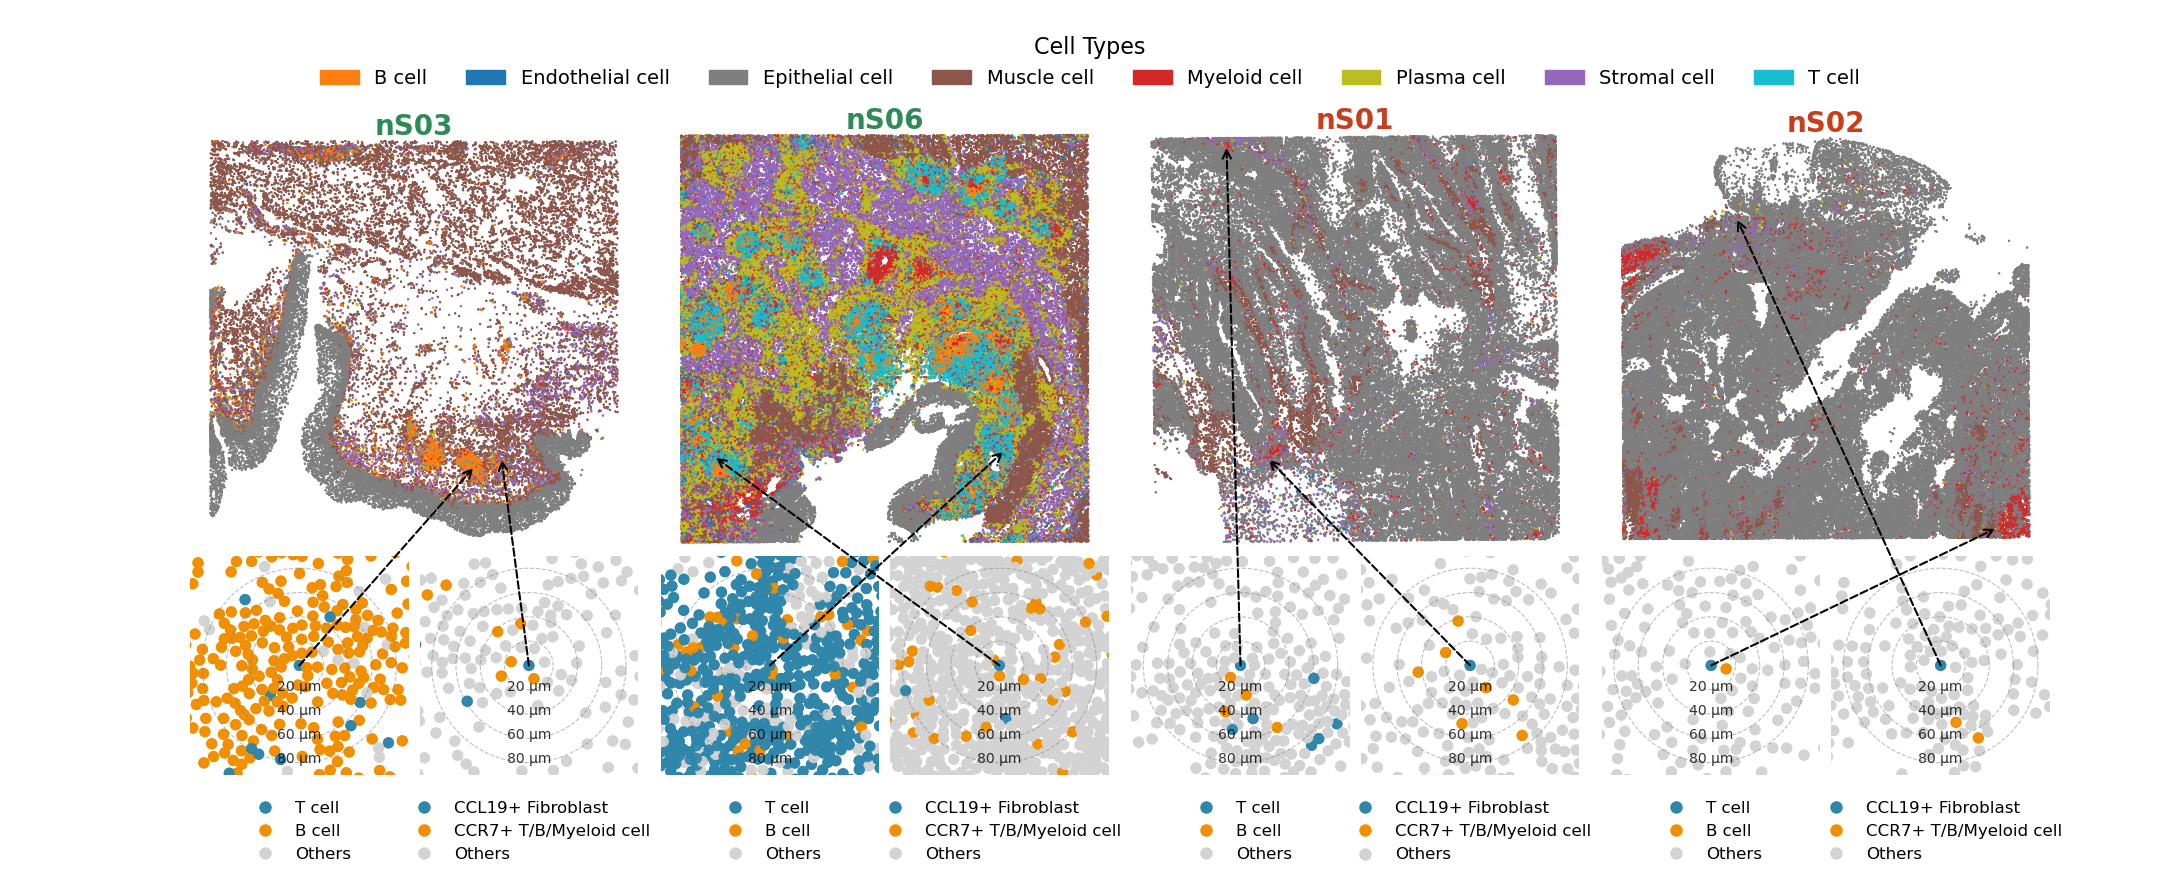

In [4]:
import scanpy as sc
adata_HD = sc.read("../h5ad/adata_HD.h5ad")
generate_final_plot(adata_HD)